# Controls: direct voltage comparison with $I = g_0 L^{0.25}$

My model, BEM conductivities (interior 100 × water, skin 0.05 × water over 0.005 cm), sink at the tail tip, sign fixed (× −1): the
predicted pair voltages of fish f are $\hat v_f = g_0\,L_f^{0.25}\,m_f$ (L in cm, $m_f$ the unit-current voltages `u_sink0` of the
conductivity runs), and the EOD goes to the fish with the smallest $\lVert r - \hat v_f\rVert$ over the 10 pairs (volts, no
normalisation). A fish without a model (no mask or midline) cannot win; an EOD whose emitter has none counts as wrong.

$g_0$ (`EOD_baseline_g0.ipynb`):
- **from the control itself**: median over the better list of the emitter's gain / $L_\mathrm{em}^{0.25}$. This uses the known
  emitter of the same recording (in-sample; it equals the median gain of the earlier known-gain test);
- **from the 4-fish recordings of the same period** (out of sample): median over the clear-emitter EODs chosen in
  `EOD_gain_vs_length_4fish_<recording>.ipynb` of gain / $L_f^{0.25}$; February 2024 (2024-02-20 21_16_26 and 18_16_24) for the 2-fish
  control (2024-02-13), October 2024 (2024-10-23 15_18_28) for the 3-fish control (2024-10-15).

For comparison, the earlier accuracies (`accuracy_overall_4pipelines.csv`): my model, shape only (max |v| = 1), and Denis' analytic
model. Two sets of EODs: all, and the better list of good frames.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

E = 0.25
PX_PER_CM = 912 / 60
OUT = 'results/baseline_g0'
REC = {
    '3-fish (2024-10-15)': dict(res='results/eod_ground_truth_3fish', cache='conductivities/model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl',
                                lengths='fish_lengths_3fish.json', fish=(0, 1, 2), emitter=0, n_all=19796, n_better=6751,
                                period=['2024-10-23T15_18_28']),
    '2-fish (2024-02-13)': dict(res='results/eod_ground_truth', cache='conductivities/model_voltages_N150_sinks0and0.05_el46ee63_bem_a453a8.pkl',
                                lengths='fish_lengths_2fish.json', fish=(0, 1), emitter=1, n_all=18770, n_better=3501,
                                period=['2024-02-20T21_16_26', '2024-02-20T18_16_24']),
}
G0 = pd.read_csv(f'{OUT}/g0_controls.csv').set_index(['recording', 'EODs'])

def wilson(k, n, z=1.96):
    p = k / n; c = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n); hw = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * (c - hw), 100 * (c + hw)

def period_g0(recs):
    s = []
    for rec in recs:
        t = pd.read_csv(f'results/eod_gain_4fish/{rec}/selected_eods.csv'); j = json.load(open(f'results/eod_gain_4fish/{rec}/fish_lengths_4fish.json'))
        L = np.array([j['fish'][str(f)]['L_px'] / j['px_per_cm'] for f in range(4)])
        s.append(t.gain_ls / L[t.fish] ** E)
    return float(np.median(pd.concat(s)))

D = {}
for name, c in REC.items():
    cache = pd.read_pickle(f"{c['res']}/{c['cache']}")
    A = pd.read_csv(f"{c['res']}/conductivities/eod_assignments.csv", index_col='row')
    assert len(cache) == len(A) == c['n_all'] and (cache.frame.to_numpy() == A.Frame.to_numpy()).all()
    better = A.Frame.isin(pd.read_csv(f"{c['res']}/good_frames_better_list.csv").frame).to_numpy()
    assert better.sum() == c['n_better']
    j = json.load(open(f"{c['res']}/{c['lengths']}"))
    D[name] = dict(R=np.stack(cache.v_rec.map(np.asarray)), M=-np.stack(cache.u_sink0.map(lambda u: np.asarray(u, float))),
                   L=np.array([j['fish'][str(f)]['L_px'] / PX_PER_CM for f in c['fish']]),
                   sets={'all EODs': np.ones(len(A), bool), 'better list of good frames': better},
                   g0={'own control (in-sample)': G0.loc[(name, 'all better-list EODs'), 'g0 = median g / L^e'],
                       'same-period 4-fish recordings (out of sample)': period_g0(c['period'])})
display(pd.DataFrame({n: {**{f'g0, {k}': v for k, v in d['g0'].items()}, 'L (cm)': d['L'].round(2).tolist()} for n, d in D.items()}).T)

,"g0, own control (in-sample)","g0, same-period 4-fish recordings (out of sample)",L (cm)
3-fish (2024-10-15),0.493815,0.456811,"[11.89, 16.55, 14.04]"
2-fish (2024-02-13),0.247369,0.198933,"[11.08, 16.49]"


## Accuracy

In [2]:
def assign(d, g0, e=E):
    pred = g0 * d['L'][None, :, None] ** e * d['M']
    dist = np.linalg.norm(d['R'][:, None] - pred, axis=2)
    dist = np.where(np.isfinite(dist), dist, np.inf)
    return np.where(np.isfinite(dist.min(1)), dist.argmin(1), -1)

rows = []
for name, d in D.items():
    em = REC[name]['emitter']
    old = pd.read_csv(f"{REC[name]['res']}/conductivities/accuracy_overall_4pipelines.csv")
    for s, m in d['sets'].items():
        for src, g0 in d['g0'].items():
            p = assign(d, g0); k, n = int((p[m] == em).sum()), int(m.sum()); lo, hi = wilson(k, n)
            rows.append({'recording': name, 'EODs': s, 'pipeline': f'numerical, voltage, g0 L^0.25, g0 from {src}', 'g0': g0,
                         '% correct': 100 * k / n, '95% CI low': lo, '95% CI high': hi, 'n EODs': n})
        for _, o in old[old.EODs == s].iterrows():
            if o.pipeline in ('numerical, sink at tail tip', 'analytic, SLEAP midline', 'analytic, mask midline'):
                rows.append({'recording': name, 'EODs': s, 'pipeline': f"earlier: {o.pipeline.replace('numerical, sink at tail tip', 'numerical, shape only (max |v| = 1)')}",
                             '% correct': o['% correct'], '95% CI low': o['95% CI low'], '95% CI high': o['95% CI high'], 'n EODs': o['n EODs']})
ACC = pd.DataFrame(rows)
ACC.to_csv(f'{OUT}/accuracy_g0_L025_controls.csv', index=False)
display(ACC.pivot_table(index='pipeline', columns=['recording', 'EODs'], values='% correct', sort=False).round(2))

recording                                          3-fish (2024-10-15)  \
EODs                                                          all EODs   
pipeline                                                                 
numerical, voltage, g0 L^0.25, g0 from own cont...               89.08   
numerical, voltage, g0 L^0.25, g0 from same-per...               88.83   
earlier: numerical, shape only (max |v| = 1)                     86.55   
earlier: analytic, SLEAP midline                                 82.44   
earlier: analytic, mask midline                                  86.99   

recording                                                                      \
EODs                                               better list of good frames   
pipeline                                                                        
numerical, voltage, g0 L^0.25, g0 from own cont...                      97.56   
numerical, voltage, g0 L^0.25, g0 from same-per...                      97.39   
earlier: numerical, shape only (max |v| = 1)                            94.50   
earlier: analytic, SLEAP midline                                        94.07   
earlier: analytic, mask midline                                         95.20   

recording                                          2-fish (2024-02-13)  \
EODs                                                          all EODs   
pipeline                                                                 
numerical, voltage, g0 L^0.25, g0 from own cont...               92.50   
numerical, voltage, g0 L^0.25, g0 from same-per...               93.34   
earlier: numerical, shape only (max |v| = 1)                     93.65   
earlier: analytic, SLEAP midline                                 89.75   
earlier: analytic, mask midline                                  93.09   

recording                                                                      
EODs                                               better list of good frames  
pipeline                                                                       
numerical, voltage, g0 L^0.25, g0 from own cont...                      97.14  
numerical, voltage, g0 L^0.25, g0 from same-per...                      97.57  
earlier: numerical, shape only (max |v| = 1)                            96.74  
earlier: analytic, SLEAP midline                                        95.94  
earlier: analytic, mask midline                                         96.97

## How much the accuracy depends on $g_0$

$g_0$ times a factor from 0.25 to 4 (the line at 1 is the control's own $g_0$; the marker is the same-period 4-fish $g_0$).

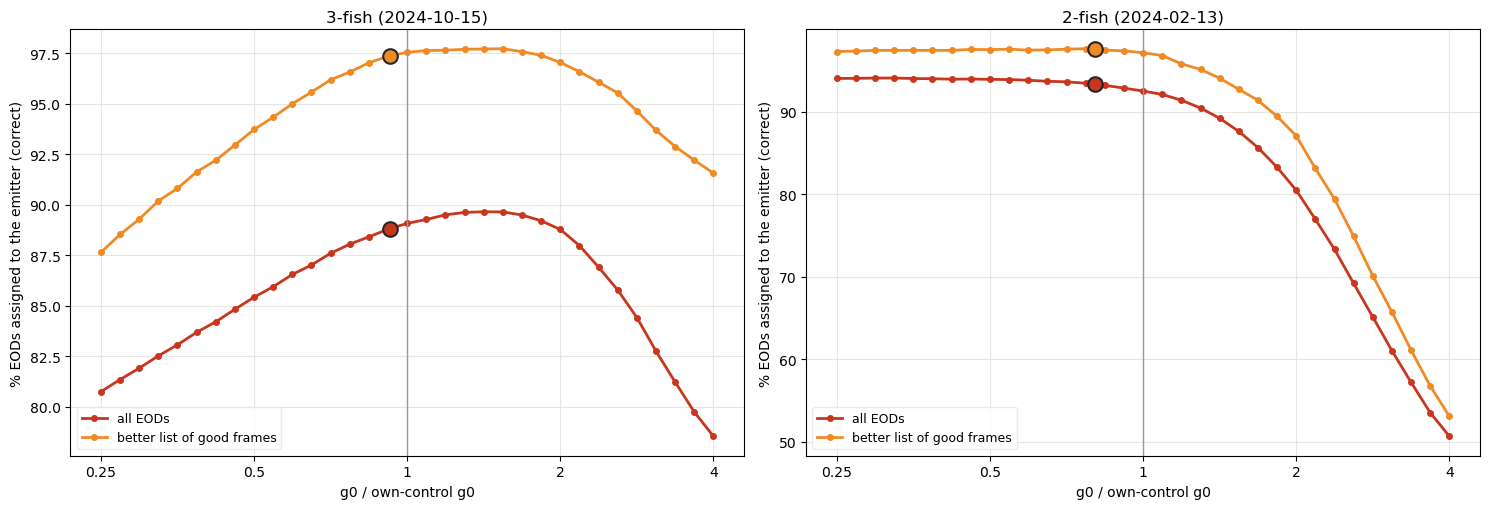

In [3]:
fac = np.exp(np.linspace(np.log(0.25), np.log(4), 33))
fig, axs = plt.subplots(1, 2, figsize=(15, 5.2), sharey=False)
COL = {'all EODs': '#C8361E', 'better list of good frames': '#F08A24'}
sens = []
for ax, (name, d) in zip(axs, D.items()):
    em = REC[name]['emitter']; g_own = d['g0']['own control (in-sample)']; g_4 = d['g0']['same-period 4-fish recordings (out of sample)']
    for s, m in d['sets'].items():
        acc = [100 * (assign(d, g_own * f)[m] == em).mean() for f in fac]
        sens += [{'recording': name, 'EODs': s, 'factor': f, 'g0': g_own * f, '% correct': a} for f, a in zip(fac, acc)]
        ax.plot(fac, acc, color=COL[s], marker='o', ms=4, lw=2, label=s)
        a4 = 100 * (assign(d, g_4)[m] == em).mean()
        ax.scatter([g_4 / g_own], [a4], s=110, color=COL[s], edgecolor='0.15', lw=1.5, zorder=3)
    ax.axvline(1, color='0.6', lw=1)
    ax.set(xscale='log', xlabel='g0 / own-control g0', ylabel='% EODs assigned to the emitter (correct)', title=name)
    ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(['0.25', '0.5', '1', '2', '4']); ax.minorticks_off(); ax.grid(True, color='#e6e6e3')
    ax.legend(fontsize=9, loc='lower left', frameon=True, facecolor='white', edgecolor='#e6e6e3')
plt.tight_layout(); fig.savefig(f'{OUT}/accuracy_vs_g0_factor.png', dpi=120); plt.show()
pd.DataFrame(sens).to_csv(f'{OUT}/accuracy_vs_g0_factor.csv', index=False)